# GARCH Volatility Live Test - ETH + BTC

Tests the GARCH model on **live data** and shows what it predicts for the next 24 hours.

**What GARCH does:**

- Models **volatility clustering** (high vol follows high vol)
- Gives a **forecast** of next-period volatility
- Does **NOT** predict direction

**What you'll see:**

1. Fetch live 1h candles (Bybit, no key)
2. Fit GARCH(1,1) and GJR-GARCH to each symbol
3. Compare forecast vs realized volatility
4. Plot volatility history + forecast
5. Decision: is volatility rising or falling?
6. What this means for options (buy now or wait)

## Setup

**Requires:** `arch` library

```
pip install arch
```

In [1]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timezone, timedelta

try:
    from arch import arch_model
    HAS_ARCH = True
    print('arch: ready')
except ImportError:
    HAS_ARCH = False
    print('arch not installed - run: pip install arch')

pd.set_option('display.width', 200)
plt.rcParams['figure.figsize'] = (13, 5)

BYBIT = 'https://api.bybit.com'
SYMBOLS = ['BTCUSDT', 'ETHUSDT']
INTERVAL = '60'   # 1h
LIMIT = 500       # 500 hours ~ 21 days
print('ready')

arch: ready
ready


## 1. Fetch live hourly candles

Bybit v5 public API. No key needed.

In [2]:
def fetch_klines(symbol, interval='60', limit=500):
    r = requests.get(f'{BYBIT}/v5/market/kline',
                     params={'category': 'linear', 'symbol': symbol,
                             'interval': interval, 'limit': limit}, timeout=15)
    r.raise_for_status()
    return r.json()['result']['list']


data = {}
for sym in SYMBOLS:
    try:
        k = fetch_klines(sym, INTERVAL, LIMIT)
        rows = [{'ts': pd.to_datetime(int(x[0]), unit='ms', utc=True).tz_convert(None),
                 'close': float(x[4]),
                 'high': float(x[2]),
                 'low': float(x[3])} for x in k]
        d = pd.DataFrame(rows).sort_values('ts').set_index('ts')
        d['ret'] = d.close.pct_change() * 100
        d = d.dropna()
        data[sym] = d
        print(f'{sym}: {len(d)} candles  {d.index.min():%Y-%m-%d %H:%M} -> {d.index.max():%Y-%m-%d %H:%M}')
    except Exception as e:
        print(f'{sym}: failed - {e}')

BTCUSDT: 499 candles  2026-10-05 16:00 -> 2026-10-26 10:00
ETHUSDT: 499 candles  2026-10-05 16:00 -> 2026-10-26 10:00


## 2. Current realized volatility (last 24h)

**What this tells you:** how much the market is *actually* moving right now.

In [3]:
print('=' * 72)
print('REALIZED VOLATILITY (actual price movement)')
print('=' * 72)
print()

for sym, d in data.items():
    ret_24h = d.ret.tail(24)
    ret_7d  = d.ret.tail(168) if len(d) > 168 else d.ret
    ret_all = d.ret

    vol_24h_ann = ret_24h.std() * np.sqrt(24 * 365)
    vol_7d_ann  = ret_7d.std() * np.sqrt(24 * 365)
    vol_all_ann = ret_all.std() * np.sqrt(24 * 365)

    print(f'{sym}:')
    print(f'  24h realized vol  : {vol_24h_ann:.1f}% (annualized)')
    print(f'  7d  realized vol  : {vol_7d_ann:.1f}%')
    print(f'  all realized vol  : {vol_all_ann:.1f}%')
    print(f'  last close        : ${d.close.iloc[-1]:,.2f}')
    print(f'  last hour return  : {d.ret.iloc[-1]:+.3f}%')
    print()

REALIZED VOLATILITY (actual price movement)

BTCUSDT:
  24h realized vol  : 26.0% (annualized)
  7d  realized vol  : 28.3%
  all realized vol  : 31.0%
  last close        : $80,398.80
  last hour return  : -0.137%

ETHUSDT:
  24h realized vol  : 37.0% (annualized)
  7d  realized vol  : 43.1%
  all realized vol  : 45.9%
  last close        : $2,329.28
  last hour return  : -0.249%



## 3. Fit GARCH(1,1) and GJR-GARCH

**GARCH(1,1):** symmetric — treats up and down moves equally

**GJR-GARCH:** asymmetric — reacts more to downside moves (crypto's characteristic)

**What this tells you:** the forecast of next-period volatility.

In [4]:
if not HAS_ARCH:
    print('Skipping GARCH - pip install arch')
else:
    results = {}
    for sym, d in data.items():
        print(f'\n{"="*50}')
        print(f'{sym}')
        print(f'{"="*50}')
        rets = d.ret.dropna()

        # GARCH(1,1)
        try:
            garch = arch_model(rets, vol='Garch', p=1, q=1,
                               dist='t', rescale=False).fit(disp='off', show_warning=False)
            fc = garch.forecast(horizon=24, reindex=False)
            var_fc = fc.variance.values[-1, :]
            vol_fc_24h = np.sqrt(var_fc.mean()) * np.sqrt(24 * 365)
            vol_fc_next = np.sqrt(var_fc[0]) * np.sqrt(24 * 365)

            print(f'GARCH(1,1):')
            print(f'  omega   : {garch.params["omega"]:.6f}')
            print(f'  alpha   : {garch.params["alpha[1]"]:.4f}')
            print(f'  beta    : {garch.params["beta[1]"]:.4f}')
            print(f'  persistence: {garch.params["alpha[1]"] + garch.params["beta[1]"]:.4f}')
            print(f'  forecast next hour vol : {vol_fc_next:.1f}% ann.')
            print(f'  forecast 24h avg vol   : {vol_fc_24h:.1f}% ann.')

            results[sym] = {'garch': garch, 'fc_24h': vol_fc_24h, 'fc_next': vol_fc_next}
        except Exception as e:
            print(f'  GARCH failed: {e}')

        # GJR-GARCH (asymmetric)
        try:
            gjr = arch_model(rets, vol='Garch', p=1, o=1, q=1,
                             dist='t', rescale=False).fit(disp='off', show_warning=False)
            fc2 = gjr.forecast(horizon=24, reindex=False)
            var_fc2 = fc2.variance.values[-1, :]
            vol_fc2_24h = np.sqrt(var_fc2.mean()) * np.sqrt(24 * 365)

            print(f'\nGJR-GARCH (asymmetric):')
            print(f'  alpha   : {gjr.params["alpha[1]"]:.4f}')
            print(f'  gamma   : {gjr.params["gamma[1]"]:.4f}  (asymmetry)')
            print(f'  beta    : {gjr.params["beta[1]"]:.4f}')
            print(f'  forecast 24h avg vol : {vol_fc2_24h:.1f}% ann.')
            if sym in results:
                results[sym]['gjr'] = gjr
                results[sym]['gjr_24h'] = vol_fc2_24h
        except Exception as e:
            print(f'  GJR-GARCH failed: {e}')


BTCUSDT
GARCH(1,1):
  omega   : 0.044942
  alpha   : 0.4512
  beta    : 0.3390
  persistence: 0.7902
  forecast next hour vol : 30.1% ann.
  forecast 24h avg vol   : 41.0% ann.

GJR-GARCH (asymmetric):
  alpha   : 0.3270
  gamma   : 0.2075  (asymmetry)
  beta    : 0.3661
  forecast 24h avg vol : 40.7% ann.

ETHUSDT
GARCH(1,1):
  omega   : 0.102560
  alpha   : 0.5227
  beta    : 0.3082
  persistence: 0.8310
  forecast next hour vol : 44.0% ann.
  forecast 24h avg vol   : 67.0% ann.

GJR-GARCH (asymmetric):
  alpha   : 0.3528
  gamma   : 0.2669  (asymmetry)
  beta    : 0.3431
  forecast 24h avg vol : 64.4% ann.


## 4. Visualize volatility history + forecast

**What this tells you:**

- Blue line = realized volatility (30-hour rolling)
- Green line = GARCH conditional volatility
- Red star = forecast for next 24 hours
- **Is volatility rising or falling?**

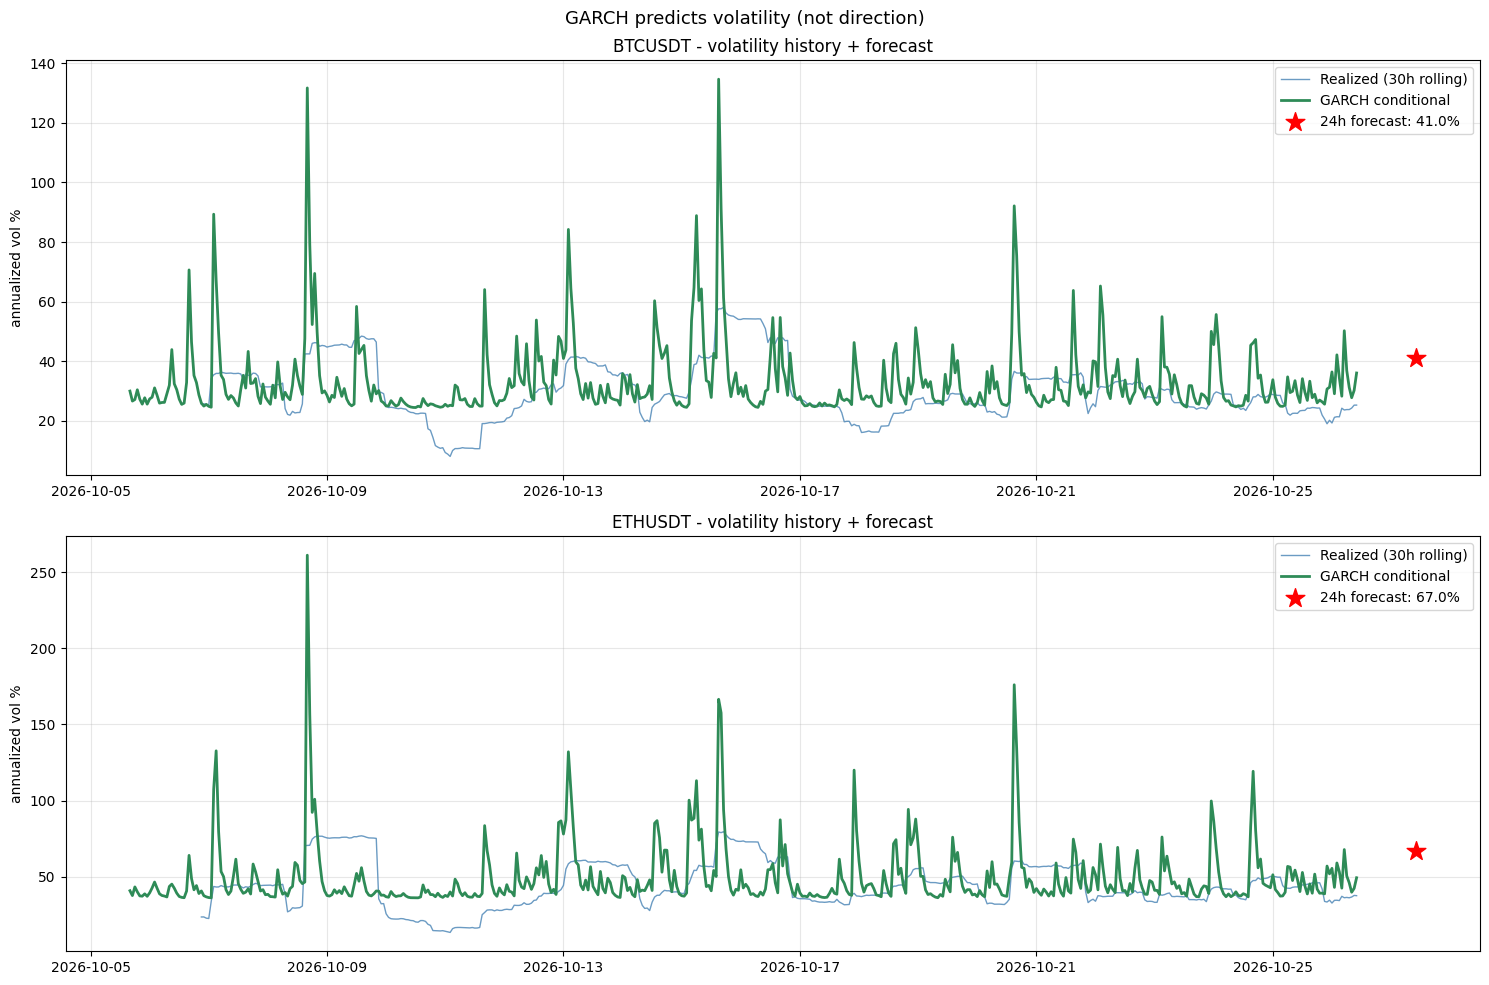

In [5]:
if HAS_ARCH and results:
    fig, axes = plt.subplots(2, 1, figsize=(15, 10))
    for ax, sym in zip(axes, SYMBOLS):
        if sym not in results: continue
        d = data[sym]
        r = results[sym]

        # realized rolling vol (30h window)
        rolling_vol = d.ret.rolling(30).std() * np.sqrt(24 * 365)

        # GARCH conditional vol
        cond_vol = r['garch'].conditional_volatility * np.sqrt(24 * 365)

        ax.plot(rolling_vol.index, rolling_vol.values, label='Realized (30h rolling)',
                color='steelblue', lw=1, alpha=0.8)
        ax.plot(rolling_vol.index, cond_vol, label='GARCH conditional',
                color='seagreen', lw=2)

        # forecast marker
        future_ts = d.index[-1] + pd.Timedelta(hours=24)
        ax.scatter(future_ts, r['fc_24h'], color='red', s=200, marker='*',
                   zorder=5, label=f'24h forecast: {r["fc_24h"]:.1f}%')

        ax.set_title(f'{sym} - volatility history + forecast')
        ax.set_ylabel('annualized vol %')
        ax.legend()
        ax.grid(alpha=0.3)

    plt.suptitle('GARCH predicts volatility (not direction)', fontsize=13)
    plt.tight_layout(); plt.show()

## 5. Rising or falling volatility?

**The decision:** compare the forecast to current realized volatility.

- **Forecast > realized by 20%+** = volatility expected to rise
- **Forecast < realized by 20%+** = volatility expected to fall
- **Within 20%** = no clear signal

In [6]:
if HAS_ARCH and results:
    print('=' * 72)
    print('VOLATILITY DIRECTION')
    print('=' * 72)
    for sym, r in results.items():
        d = data[sym]
        realized_24h = d.ret.tail(24).std() * np.sqrt(24 * 365)
        forecast = r['fc_24h']
        ratio = forecast / realized_24h if realized_24h > 0 else 1

        print(f'\n{sym}:')
        print(f'  Current realized (24h) : {realized_24h:.1f}%')
        print(f'  GARCH forecast (24h)   : {forecast:.1f}%')
        print(f'  Ratio (forecast/real)  : {ratio:.2f}x')
        if ratio > 1.20:
            print(f'  -> VOLATILITY EXPECTED TO RISE')
            print(f'     Good time to BUY options (premium will expand)')
        elif ratio < 0.80:
            print(f'  -> VOLATILITY EXPECTED TO FALL')
            print(f'     BAD time to buy options (premium will decay)')
        else:
            print(f'  -> VOLATILITY STABLE')
            print(f'     No clear IV edge from vol direction')

VOLATILITY DIRECTION

BTCUSDT:
  Current realized (24h) : 26.0%
  GARCH forecast (24h)   : 41.0%
  Ratio (forecast/real)  : 1.58x
  -> VOLATILITY EXPECTED TO RISE
     Good time to BUY options (premium will expand)

ETHUSDT:
  Current realized (24h) : 37.0%
  GARCH forecast (24h)   : 67.0%
  Ratio (forecast/real)  : 1.81x
  -> VOLATILITY EXPECTED TO RISE
     Good time to BUY options (premium will expand)


## 6. What this means for options buyers

**The connection:** GARCH forecast → IV expectation → option value.

- If GARCH says vol rises → IV likely rises → **buy options now**
- If GARCH says vol falls → IV likely falls → **wait or sell**
- The market often prices this in advance (IV already elevated)

In [7]:
if HAS_ARCH and results:
    print('=' * 72)
    print('OPTIONS IMPLICATION')
    print('=' * 72)
    print()
    for sym, r in results.items():
        d = data[sym]
        realized_24h = d.ret.tail(24).std() * np.sqrt(24 * 365)
        forecast = r['fc_24h']
        ratio = forecast / realized_24h if realized_24h > 0 else 1

        print(f'{sym}:')
        print(f'  GARCH 24h forecast   : {forecast:.1f}%')
        print(f'  Current realized vol : {realized_24h:.1f}%')

        if ratio > 1.20:
            print(f'  ✓ Volatility likely to expand')
            print(f'    - BUYING options is favoured')
            print(f'    - Look for cheap premium (low IV rank)')
            print(f'    - Buy 7-30 day options to capture IV expansion')
        elif ratio < 0.80:
            print(f'  ✗ Volatility likely to contract')
            print(f'    - BUYING options is unfavourable')
            print(f'    - If you must trade, use SHORT-dated (less vega)')
            print(f'    - Or wait for a better entry')
        else:
            print(f'  ~ Volatility stable')
            print(f'    - Options fair priced')
            print(f'    - Direction matters more than vol')
        print()

OPTIONS IMPLICATION

BTCUSDT:
  GARCH 24h forecast   : 41.0%
  Current realized vol : 26.0%
  ✓ Volatility likely to expand
    - BUYING options is favoured
    - Look for cheap premium (low IV rank)
    - Buy 7-30 day options to capture IV expansion

ETHUSDT:
  GARCH 24h forecast   : 67.0%
  Current realized vol : 37.0%
  ✓ Volatility likely to expand
    - BUYING options is favoured
    - Look for cheap premium (low IV rank)
    - Buy 7-30 day options to capture IV expansion



## 7. Summary

One-page answer: should I buy options today based on GARCH?

In [8]:
print('=' * 72)
print('GARCH VOLATILITY SUMMARY')
print('=' * 72)
print()

if not HAS_ARCH:
    print('arch not installed - no GARCH results')
elif not results:
    print('GARCH failed - no results')
else:
    for sym, r in results.items():
        d = data[sym]
        realized = d.ret.tail(24).std() * np.sqrt(24 * 365)
        forecast = r['fc_24h']
        ratio = forecast / realized if realized > 0 else 1

        if 'volume' in d.columns:
            current_vol  = float(d.volume.iloc[-1])
            avg_24h_vol  = float(d.volume.tail(24).mean())
            avg_7d_vol   = float(d.volume.tail(168).mean()) if len(d) >= 168 else avg_24h_vol
            vol_ratio_24h = current_vol / avg_24h_vol if avg_24h_vol > 0 else 0
            vol_ratio_7d  = current_vol / avg_7d_vol  if avg_7d_vol  > 0 else 0
        else:
            current_vol = avg_24h_vol = avg_7d_vol = 0
            vol_ratio_24h = vol_ratio_7d = 0

        print(f'{sym}  (${d.close.iloc[-1]:,.2f})')
        print(f'  Realized 24h vol    : {realized:>6.1f}%')
        print(f'  GARCH 24h forecast  : {forecast:>6.1f}%')
        print(f'  Ratio               : {ratio:>6.2f}x')
        print()
        print(f'  CURRENT VOLUME')
        print(f'    Last candle       : {current_vol:>15,.2f}')
        print(f'    24h average       : {avg_24h_vol:>15,.2f}')
        print(f'    7d average        : {avg_7d_vol:>15,.2f}')
        print(f'    vs 24h avg        : {vol_ratio_24h:>6.2f}x')
        print(f'    vs 7d avg         : {vol_ratio_7d:>6.2f}x')
        print()

        if ratio > 1.20 and vol_ratio_24h > 1.3:
            print(f'  VERDICT: STRONG - vol rising + volume confirming')
            print(f'           BUY OPTIONS (both vol and volume support move)')
        elif ratio > 1.20 and vol_ratio_24h < 0.7:
            print(f'  VERDICT: WEAK - vol forecast rising but volume quiet')
            print(f'           Low conviction. Consider waiting for volume.')
        elif ratio > 1.20:
            print(f'  VERDICT: BUY CALLS OR PUTS (vol rising, volume normal)')
        elif ratio < 0.80:
            print(f'  VERDICT: WAIT (vol falling, premium will decay)')
        else:
            print(f'  VERDICT: NEUTRAL (no vol edge)')
        print()

    print('=' * 72)
    print('HOW TO USE THIS')
    print('=' * 72)
    print()
    print('  GARCH tells you WHEN to buy options (vol regime)')
    print('  Volume tells you if the market is CONFIRMING the move')
    print('  Neither tells you WHICH direction (call vs put)')
    print()
    print('  Volume interpretation:')
    print('    > 1.5x avg  = strong interest, move is real')
    print('    0.5-1.5x    = normal activity')
    print('    < 0.5x avg  = dead market, avoid entries')
    print()
    print('  Combine with:')
    print('    - pcr.ipynb      (direction)')
    print('    - oi_analysis    (positioning)')
    print('    - funding        (crowding)')
    print()
    print('  Trade only when vol rising + volume confirming + direction is clear.')

GARCH VOLATILITY SUMMARY

BTCUSDT  ($80,398.80)
  Realized 24h vol    :   26.0%
  GARCH 24h forecast  :   41.0%
  Ratio               :   1.58x

  CURRENT VOLUME
    Last candle       :            0.00
    24h average       :            0.00
    7d average        :            0.00
    vs 24h avg        :   0.00x
    vs 7d avg         :   0.00x

  VERDICT: WEAK - vol forecast rising but volume quiet
           Low conviction. Consider waiting for volume.

ETHUSDT  ($2,329.28)
  Realized 24h vol    :   37.0%
  GARCH 24h forecast  :   67.0%
  Ratio               :   1.81x

  CURRENT VOLUME
    Last candle       :            0.00
    24h average       :            0.00
    7d average        :            0.00
    vs 24h avg        :   0.00x
    vs 7d avg         :   0.00x

  VERDICT: WEAK - vol forecast rising but volume quiet
           Low conviction. Consider waiting for volume.

HOW TO USE THIS

  GARCH tells you WHEN to buy options (vol regime)
  Volume tells you if the market is CONFI

## Notes

**What GARCH is good for:**

- Forecasting volatility magnitude (proven academic model)
- Detecting volatility regime changes
- Timing option entries (buy when vol is cheap and rising)

**What GARCH is NOT good for:**

- Predicting price direction
- Working alone (needs a directional signal)
- Very short timeframes (1h GARCH is noisy; daily is more stable)

**Model notes:**

- GARCH(1,1): symmetric, standard baseline
- GJR-GARCH: asymmetric, better for crypto's downside skew
- t-distribution: captures fat tails (crypto has these)
- Persistence = alpha + beta; close to 1 = vol shocks are long-lasting

**Data:**

- Live from Bybit v5 public API
- 500 hourly candles (~21 days)
- No storage, no keys
- Re-run for fresh forecast